# UCS420 Lab Assignment 10 - NLP using Python 2
Feature extraction from text, sentiment analysis and text generation

Gurkirpa Singh Sarao - 1024170378

In [ ]:
import re
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

---
## Q1. Paragraph preprocessing
My paragraph is on mathematics.

In [ ]:
# Q1
text = ("Mathematics is a fascinating field because it can model almost anything, from abstract "
        "structures in higher dimensions to stochastic processes in real-world scenarios. "
        "We don't often focus on its applications while chasing theory or grades, and that's partly "
        "why it has a poor reputation among students. Yet for all the sciences, it is the common "
        "language that expresses ideas without ambiguity. Physicists, economists and computer "
        "scientists rely on the same equations and proofs, and probability theory underpins both "
        "finance and machine learning. Improving the way it is taught is another thought-provoking "
        "challenge, especially in India, which has produced great mathematicians like Aryabhata, "
        "Brahmagupta and Ramanujan. Better teaching would help more students see mathematics as a "
        "creative pursuit rather than a memorised subject.")
print(text)

Mathematics is a fascinating field because it can model almost anything, from abstract structures in higher dimensions to stochastic processes in real-world scenarios. We don't often focus on its applications while chasing theory or grades, and that's partly why it has a poor reputation among students. Yet for all the sciences, it is the common language that expresses ideas without ambiguity. Physicists, economists and computer scientists rely on the same equations and proofs, and probability theory underpins both finance and machine learning. Improving the way it is taught is another thought-provoking challenge, especially in India, which has produced great mathematicians like Aryabhata, Brahmagupta and Ramanujan. Better teaching would help more students see mathematics as a creative pursuit rather than a memorised subject.


In [ ]:
# 1. lowercase and remove punctuation
clean = re.sub(r"[^\w\s]", "", text.lower())
print(clean)

mathematics is a fascinating field because it can model almost anything from abstract structures in higher dimensions to stochastic processes in realworld scenarios we dont often focus on its applications while chasing theory or grades and thats partly why it has a poor reputation among students yet for all the sciences it is the common language that expresses ideas without ambiguity physicists economists and computer scientists rely on the same equations and proofs and probability theory underpins both finance and machine learning improving the way it is taught is another thoughtprovoking challenge especially in india which has produced great mathematicians like aryabhata brahmagupta and ramanujan better teaching would help more students see mathematics as a creative pursuit rather than a memorised subject


In [ ]:
# 2. sentence and word tokens
sents = sent_tokenize(text)      # needs the original punctuation
words = word_tokenize(clean)
print("Sentences:", len(sents))
for s in sents:
    print("-", s)
print("\nWords:", len(words))
print(words)

Sentences: 6
- Mathematics is a fascinating field because it can model almost anything, from abstract structures in higher dimensions to stochastic processes in real-world scenarios.
- We don't often focus on its applications while chasing theory or grades, and that's partly why it has a poor reputation among students.
- Yet for all the sciences, it is the common language that expresses ideas without ambiguity.
- Physicists, economists and computer scientists rely on the same equations and proofs, and probability theory underpins both finance and machine learning.
- Improving the way it is taught is another thought-provoking challenge, especially in India, which has produced great mathematicians like Aryabhata, Brahmagupta and Ramanujan.
- Better teaching would help more students see mathematics as a creative pursuit rather than a memorised subject.

Words: 122
['mathematics', 'is', 'a', 'fascinating', 'field', 'because', 'it', 'can', 'model', 'almost', 'anything', 'from', 'abstract', 

In [ ]:
# 3. split() vs word_tokenize() on the original text
sp = text.split()
wt = word_tokenize(text)
print("split()        :", len(sp), "tokens")
print("word_tokenize():", len(wt), "tokens\n")
print("split()        :", sp[:22])
print("word_tokenize():", wt[:26])
print("\nOnly in split()        :", sorted(set(sp) - set(wt)))
print("Only in word_tokenize():", sorted(set(wt) - set(sp)))

split()        : 122 tokens
word_tokenize(): 138 tokens

split()        : ['Mathematics', 'is', 'a', 'fascinating', 'field', 'because', 'it', 'can', 'model', 'almost', 'anything,', 'from', 'abstract', 'structures', 'in', 'higher', 'dimensions', 'to', 'stochastic', 'processes', 'in', 'real-world']
word_tokenize(): ['Mathematics', 'is', 'a', 'fascinating', 'field', 'because', 'it', 'can', 'model', 'almost', 'anything', ',', 'from', 'abstract', 'structures', 'in', 'higher', 'dimensions', 'to', 'stochastic', 'processes', 'in', 'real-world', 'scenarios', '.', 'We']

Only in split()        : ['Aryabhata,', 'India,', 'Physicists,', 'Ramanujan.', 'ambiguity.', 'anything,', 'challenge,', "don't", 'grades,', 'learning.', 'proofs,', 'scenarios.', 'sciences,', 'students.', 'subject.', "that's"]
Only in word_tokenize(): ["'s", ',', '.', 'Aryabhata', 'India', 'Physicists', 'Ramanujan', 'ambiguity', 'anything', 'challenge', 'do', 'grades', 'learning', "n't", 'proofs', 'scenarios', 'sciences', 'subjec

`split()` only breaks on whitespace, so punctuation stays stuck to words (`anything,`, `scenarios.`, `don't`). `word_tokenize()` separates punctuation into its own tokens and splits contractions as `do` + `n't` and `that` + `'s`. It keeps hyphenated words like `real-world` and `thought-provoking` together. So it gives more tokens overall, but each token is a cleaner word or symbol.

In [ ]:
# 4. remove stopwords
filt = [w for w in words if w not in STOP]
print(len(words), "->", len(filt), "words")
print(filt)

122 -> 75 words
['mathematics', 'fascinating', 'field', 'model', 'almost', 'anything', 'abstract', 'structures', 'higher', 'dimensions', 'stochastic', 'processes', 'realworld', 'scenarios', 'dont', 'often', 'focus', 'applications', 'chasing', 'theory', 'grades', 'thats', 'partly', 'poor', 'reputation', 'among', 'students', 'yet', 'sciences', 'common', 'language', 'expresses', 'ideas', 'without', 'ambiguity', 'physicists', 'economists', 'computer', 'scientists', 'rely', 'equations', 'proofs', 'probability', 'theory', 'underpins', 'finance', 'machine', 'learning', 'improving', 'way', 'taught', 'another', 'thoughtprovoking', 'challenge', 'especially', 'india', 'produced', 'great', 'mathematicians', 'like', 'aryabhata', 'brahmagupta', 'ramanujan', 'better', 'teaching', 'would', 'help', 'students', 'see', 'mathematics', 'creative', 'pursuit', 'rather', 'memorised', 'subject']


[('mathematics', 2), ('theory', 2), ('students', 2), ('fascinating', 1), ('field', 1), ('model', 1), ('almost', 1), ('anything', 1), ('abstract', 1), ('structures', 1)]


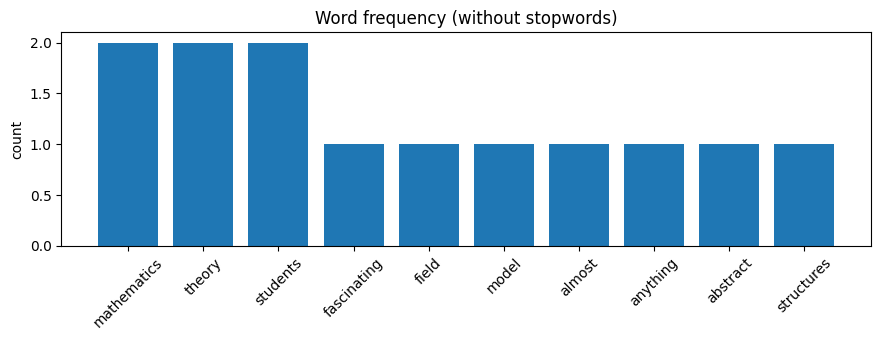

In [ ]:
# 5. frequency distribution
fd = nltk.FreqDist(filt)
print(fd.most_common(10))

top = fd.most_common(10)
plt.figure(figsize=(9, 3.5))
plt.bar([w for w, c in top], [c for w, c in top])
plt.xticks(rotation=45)
plt.ylabel("count")
plt.title("Word frequency (without stopwords)")
plt.tight_layout()
plt.show()

---
## Q2. Stemming and lemmatization on the same paragraph

In [ ]:
# Q2
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# 1. only alphabetic words
alpha = re.findall(r"[a-zA-Z]+", text.lower())
print(alpha)

# 2. remove stopwords
alpha = [w for w in alpha if w not in STOP]
print("\nAfter stopwords:", alpha)

['mathematics', 'is', 'a', 'fascinating', 'field', 'because', 'it', 'can', 'model', 'almost', 'anything', 'from', 'abstract', 'structures', 'in', 'higher', 'dimensions', 'to', 'stochastic', 'processes', 'in', 'real', 'world', 'scenarios', 'we', 'don', 't', 'often', 'focus', 'on', 'its', 'applications', 'while', 'chasing', 'theory', 'or', 'grades', 'and', 'that', 's', 'partly', 'why', 'it', 'has', 'a', 'poor', 'reputation', 'among', 'students', 'yet', 'for', 'all', 'the', 'sciences', 'it', 'is', 'the', 'common', 'language', 'that', 'expresses', 'ideas', 'without', 'ambiguity', 'physicists', 'economists', 'and', 'computer', 'scientists', 'rely', 'on', 'the', 'same', 'equations', 'and', 'proofs', 'and', 'probability', 'theory', 'underpins', 'both', 'finance', 'and', 'machine', 'learning', 'improving', 'the', 'way', 'it', 'is', 'taught', 'is', 'another', 'thought', 'provoking', 'challenge', 'especially', 'in', 'india', 'which', 'has', 'produced', 'great', 'mathematicians', 'like', 'aryabha

In [ ]:
# 3, 4. stemming and lemmatization
ps = PorterStemmer()
wnl = WordNetLemmatizer()

def wn_pos(t):
    if t.startswith("J"):
        return wordnet.ADJ
    if t.startswith("V"):
        return wordnet.VERB
    if t.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

rows = []
for w, t in pos_tag(alpha):
    rows.append([w, t, ps.stem(w), wnl.lemmatize(w, wn_pos(t))])

q2 = pd.DataFrame(rows, columns=["Word", "POS", "Stem", "Lemma"]).drop_duplicates("Word")
print(q2.to_string(index=False))

          Word POS          Stem         Lemma
   mathematics NNS      mathemat   mathematics
   fascinating VBG        fascin     fascinate
         field  NN         field         field
         model  NN         model         model
        almost  RB        almost        almost
      anything  NN         anyth      anything
      abstract  JJ      abstract      abstract
    structures VBZ      structur     structure
        higher JJR        higher          high
    dimensions NNS        dimens     dimension
    stochastic  JJ      stochast    stochastic
     processes NNS       process       process
          real  JJ          real          real
         world  NN         world         world
     scenarios NNS      scenario      scenario
         often  RB         often         often
         focus VBP          focu         focus
  applications NNS        applic   application
       chasing VBG         chase         chase
        theory  NN        theori        theory
        grade

In [ ]:
# 5. words where they differ
d = q2[q2.Stem != q2.Lemma]
print(len(d), "of", len(q2), "words differ\n")
print(d.to_string(index=False))

33 of 72 words differ

        Word POS     Stem       Lemma
 mathematics NNS mathemat mathematics
 fascinating VBG   fascin   fascinate
    anything  NN    anyth    anything
  structures VBZ structur   structure
      higher JJR   higher        high
  dimensions NNS   dimens   dimension
  stochastic  JJ stochast  stochastic
       focus VBP     focu       focus
applications NNS   applic application
      theory  NN   theori      theory
      partly  RB   partli      partly
  reputation  NN    reput  reputation
    sciences NNS   scienc     science
    language  NN  languag    language
   ambiguity  NN   ambigu   ambiguity
    computer  NN   comput    computer
        rely VBP     reli        rely
   equations NNS    equat    equation
 probability  NN  probabl probability
   underpins NNS underpin   underpins
     finance  NN   financ     finance
     machine  NN   machin     machine
   improving VBG   improv     improve
      taught VBD   taught       teach
     another  DT    anoth  

**Comparison:** the Porter stemmer chops suffixes by rule, so it often gives non-words like `mathemat`, `theori`, `comput` and `especi`, and it can't handle irregular forms (`taught` stays `taught`). The lemmatizer looks the word up in WordNet using the POS tag and returns a real dictionary form: `taught` → `teach`, `better` → `good`, `higher` → `high`, `dimensions` → `dimension`. The lemmatizer is only as good as the tagger, though. `underpins` was tagged as a noun, so it stayed `underpins`, and `teaching` was tagged as a noun, so it was left unchanged while the stemmer gave `teach`.

I'd use **stemming** when speed and recall matter more than readability, e.g. search engines or bag-of-words features over a large corpus, where `teaching` and `teach` only need to land in the same bucket. I'd use **lemmatization** when the output is read by people or the meaning matters, e.g. chatbots, question answering or reporting keywords, since it keeps real words and handles irregular forms like `taught`.

---
## Q3. Bag of Words and TF-IDF
Three short texts, summarised from articles in today's papers (23 Oct 2026).

In [ ]:
# Q3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = [
    # The Hindu, Economic Notes
    "Keynes argued that the economy cannot be understood as a sum of individual decisions. "
    "Investment by businesses, driven by profit expectations, decides output and employment, "
    "and investment matters more than savings or interest rates.",
    # Indian Express, Harish Damodaran
    "Indian agriculture faces the fossilisation of farming, as it depends on diesel and fertilisers "
    "made from oil and gas, and the fuelisation of food, as crops are diverted to ethanol. "
    "Rising oil prices hurt farming from both sides.",
    # Indian Express, editorial
    "Blaming protests on a foreign hand denies citizens their legitimate concerns. "
    "The government should stop blaming a foreign hand and honestly reckon with its own failures.",
]
names = ["Keynes", "Agriculture", "Foreign hand"]

In [ ]:
# 1. Bag of Words
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(docs)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=names)
print("Vocabulary size:", len(cv.vocabulary_))
bow_df

Vocabulary size: 50


,agriculture,argued,blaming,businesses,citizens,concerns,crops,decides,decisions,denies,...,profit,protests,rates,reckon,rising,savings,sides,stop,sum,understood
Keynes,0,1,0,1,0,0,0,1,1,0,...,1,0,1,0,0,1,0,0,1,1
Agriculture,1,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,1,0,0,0
Foreign hand,0,0,2,0,1,1,0,0,0,1,...,0,1,0,1,0,0,0,1,0,0


In [ ]:
# 2. TF-IDF
tv = TfidfVectorizer(stop_words="english")
tf = tv.fit_transform(docs)
tf_df = pd.DataFrame(tf.toarray(), columns=tv.get_feature_names_out(), index=names).round(3)
tf_df

,agriculture,argued,blaming,businesses,citizens,concerns,crops,decides,decisions,denies,...,profit,protests,rates,reckon,rising,savings,sides,stop,sum,understood
Keynes,0.0,0.218,0.000,0.218,0.000,0.000,0.0,0.218,0.218,0.000,...,0.218,0.000,0.218,0.000,0.0,0.218,0.0,0.000,0.218,0.218
Agriculture,0.2,0.000,0.000,0.000,0.000,0.000,0.2,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.2,0.000,0.2,0.000,0.000,0.000
Foreign hand,0.0,0.000,0.426,0.000,0.213,0.213,0.0,0.000,0.000,0.213,...,0.000,0.213,0.000,0.213,0.0,0.000,0.0,0.213,0.000,0.000


In [ ]:
# 3. top 3 keywords per text
for n in names:
    top = tf_df.loc[n].sort_values(ascending=False).head(3)
    print(n, ":", list(zip(top.index, top.values)))

Keynes : [('investment', np.float64(0.436)), ('argued', np.float64(0.218)), ('economy', np.float64(0.218))]
Agriculture : [('oil', np.float64(0.4)), ('farming', np.float64(0.4)), ('ethanol', np.float64(0.2))]
Foreign hand : [('blaming', np.float64(0.426)), ('foreign', np.float64(0.426)), ('hand', np.float64(0.426))]


**Interpretation:** the three texts share no words after stopword removal, so every word gets the same IDF. The ranking therefore comes down to term frequency: the words repeated within a text score highest, and they capture what the text is about.
- **Keynes:** `investment` leads, which is the core of the article's argument (investment, not savings, drives the economy).
- **Agriculture:** `oil` and `farming` lead, which matches the article's point that farming depends on oil, from both diesel/fertilisers and the push toward fuel crops.
- **Foreign hand:** `foreign`, `hand` and `blaming` lead, which summarises the editorial in three words.

Words that appear only once in a text tie with each other, so the third keyword is sometimes just one of several equal scores. With a larger set of articles, IDF would also push down words that are common across many texts.

---
## Q4. Text similarity: Transformers vs Mamba
Two texts based on the papers *Attention Is All You Need* (Vaswani et al., 2017) and *Mamba: Linear-Time Sequence Modeling with Selective State Spaces* (Gu and Dao, 2023).

In [ ]:
# Q4
t1 = ("The Transformer is a neural network architecture for sequence modelling introduced in 2017. "
      "It drops recurrence and relies on self-attention, where every token attends to every other token. "
      "This lets the model capture long-range dependencies and train in parallel on GPUs. "
      "The cost is that attention grows quadratically with sequence length, so long sequences are expensive. "
      "Transformers now power most large language models.")
t2 = ("Mamba is a sequence modelling architecture based on selective state space models, introduced in 2023. "
      "Instead of attention, it carries a hidden state along the sequence and lets each token decide what to keep or forget. "
      "Its cost grows linearly with sequence length, so it handles long sequences efficiently. "
      "A hardware-aware parallel scan keeps training fast on GPUs. "
      "Mamba matches Transformers of similar size on language modelling with faster inference.")

In [ ]:
# 1. preprocess and tokenize
wnl = WordNetLemmatizer()

def prep(t):
    toks = re.findall(r"[a-z]+", t.lower())
    return [wnl.lemmatize(w) for w in toks if w not in STOP]

p1, p2 = prep(t1), prep(t2)
print("Text 1:", p1)
print("\nText 2:", p2)

Text 1: ['transformer', 'neural', 'network', 'architecture', 'sequence', 'modelling', 'introduced', 'drop', 'recurrence', 'relies', 'self', 'attention', 'every', 'token', 'attends', 'every', 'token', 'let', 'model', 'capture', 'long', 'range', 'dependency', 'train', 'parallel', 'gpus', 'cost', 'attention', 'grows', 'quadratically', 'sequence', 'length', 'long', 'sequence', 'expensive', 'transformer', 'power', 'large', 'language', 'model']

Text 2: ['mamba', 'sequence', 'modelling', 'architecture', 'based', 'selective', 'state', 'space', 'model', 'introduced', 'instead', 'attention', 'carry', 'hidden', 'state', 'along', 'sequence', 'let', 'token', 'decide', 'keep', 'forget', 'cost', 'grows', 'linearly', 'sequence', 'length', 'handle', 'long', 'sequence', 'efficiently', 'hardware', 'aware', 'parallel', 'scan', 'keep', 'training', 'fast', 'gpus', 'mamba', 'match', 'transformer', 'similar', 'size', 'language', 'modelling', 'faster', 'inference']


In [ ]:
# 2a. Jaccard similarity
a, b = set(p1), set(p2)
jac = len(a & b) / len(a | b)
print("Common words:", sorted(a & b))
print("Jaccard similarity:", round(jac, 3))

Common words: ['architecture', 'attention', 'cost', 'gpus', 'grows', 'introduced', 'language', 'length', 'let', 'long', 'model', 'modelling', 'parallel', 'sequence', 'token', 'transformer']
Jaccard similarity: 0.281


In [ ]:
# 2b. Cosine similarity with TF-IDF
from sklearn.metrics.pairwise import cosine_similarity

tv2 = TfidfVectorizer()
m = tv2.fit_transform([" ".join(p1), " ".join(p2)])
cos = cosine_similarity(m[0], m[1])[0][0]
print("Cosine similarity:", round(cos, 3))

Cosine similarity: 0.375


**Analysis:** both texts are about sequence models, so they share words like `sequence`, `attention`, `token`, `gpus`, `language` and `modelling`. Jaccard only checks whether a word is present, so one shared word counts the same as any other, whether it's `sequence` (repeated many times) or `introduced` (a one-off). Cosine with TF-IDF uses counts and weights. Shared words that are frequent in both texts, like `sequence`, push the score up, while words that appear in only one text get a higher IDF and pull the vectors apart.

In my case cosine gives the better insight. The two texts are about the same problem and use the same core vocabulary repeatedly, which cosine picks up and Jaccard underweights. Jaccard is still useful as a quick, easy-to-explain overlap measure for short texts or keyword sets.

---
## Q5. Sentiment analysis
Short reviews of *A Mathematician's Apology* by G. H. Hardy. TextBlob gives polarity and subjectivity, and VADER's compound score is used for the final label (≥ 0.05 positive, ≤ −0.05 negative, otherwise neutral).

In [ ]:
# Q5
from textblob import TextBlob
from nltk.sentiment import SentimentIntensityAnalyzer

reviews = [
    "A beautiful and honest little book. Hardy's love for pure mathematics shines on every page.",
    "Elegant writing and a brilliant defence of mathematics as an art. I enjoyed it thoroughly.",
    "Short, thoughtful and surprisingly moving, especially the parts about growing old.",
    "I found his dismissal of applied mathematics arrogant and frankly disappointing.",
    "The book is about 90 pages long and was first published in 1940.",
    "Some sections felt dull and repetitive, and the ending was weak.",
]

sia = SentimentIntensityAnalyzer()

def label(c):
    if c >= 0.05:
        return "Positive"
    if c <= -0.05:
        return "Negative"
    return "Neutral"

rows = []
for r in reviews:
    tb = TextBlob(r).sentiment
    c = sia.polarity_scores(r)["compound"]
    rows.append([r, round(tb.polarity, 3), round(tb.subjectivity, 3), c, label(c)])

q5 = pd.DataFrame(rows, columns=["Review", "Polarity", "Subjectivity", "VADER", "Label"])
pd.set_option("display.max_colwidth", 60)
q5

,Review,Polarity,Subjectivity,VADER,Label
0,A beautiful and honest little book. Hardy's love for pur...,0.395,0.700,0.9029,Positive
1,Elegant writing and a brilliant defence of mathematics a...,0.633,0.900,0.8910,Positive
2,"Short, thoughtful and surprisingly moving, especially th...",0.240,0.500,0.6705,Positive
3,I found his dismissal of applied mathematics arrogant an...,-0.600,0.700,-0.7506,Negative
4,The book is about 90 pages long and was first published ...,0.100,0.367,0.0000,Neutral
5,"Some sections felt dull and repetitive, and the ending w...",-0.306,0.458,-0.7650,Negative


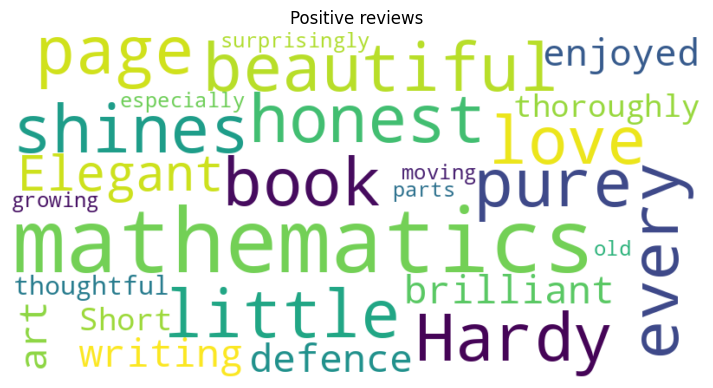

In [ ]:
# word cloud of positive reviews
from wordcloud import WordCloud, STOPWORDS

pos = " ".join(q5[q5.Label == "Positive"].Review)
wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=STOPWORDS, random_state=1).generate(pos)

plt.figure(figsize=(9, 4.5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Positive reviews")
plt.show()

The factual review ("about 90 pages long… published in 1940") comes out neutral with VADER, but TextBlob gives it a small positive polarity (0.1). This is because TextBlob's lexicon scores `first` as +0.25 and `long` as −0.05. Its low subjectivity shows it's a statement of fact rather than an opinion.

---
## Q6. Text generation with an LSTM
Training paragraph on the Indian monsoon (about 110 words). It repeats some phrases on purpose, which helps a small model learn patterns.

In [ ]:
# Q6
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide tensorflow info logs

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.keras.utils.set_random_seed(42)

para = ("The monsoon arrives in June and the dry fields wake up. The first rain falls on the dust "
        "and the air smells of wet earth. The farmers look at the dark clouds and the children run "
        "out into the rain. The rain fills the rivers, the rain fills the wells, and the rain fills "
        "the hearts of the farmers with hope. When the clouds stay away, the fields stay dry and the "
        "farmers wait. When the clouds return, the green returns to the fields and the songs return "
        "to the villages. The monsoon is not just rain, it is the rhythm of life in India.")

# 1. tokenize
tok = Tokenizer()
tok.fit_on_texts([para])
total = len(tok.word_index) + 1
print("Vocabulary size:", total)
print(list(tok.word_index.items())[:10])

Vocabulary size: 53
[('the', 1), ('and', 2), ('rain', 3), ('fields', 4), ('of', 5), ('farmers', 6), ('clouds', 7), ('fills', 8), ('monsoon', 9), ('in', 10)]


In [ ]:
# 2. input sequences (n-grams within each sentence)
seqs = []
for line in para.split("."):
    ids = tok.texts_to_sequences([line])[0]
    for i in range(1, len(ids)):
        seqs.append(ids[:i + 1])

maxlen = max(len(s) for s in seqs)
seqs = pad_sequences(seqs, maxlen=maxlen, padding="pre")
X, y = seqs[:, :-1], seqs[:, -1]
print("Sequences:", len(seqs), " max length:", maxlen)

Sequences: 98  max length: 21


In [ ]:
# model
model = Sequential([
    Embedding(total, 32),
    LSTM(100),
    Dense(total, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, maxlen - 1))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 32)         │         1,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        53,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 53)             │         5,353 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,249 (235.35 KB)

 Trainable params: 60,249 (235.35 KB)

 Non-trainable params: 0 (0.00 B)

Final loss: 0.175
Final accuracy: 0.939


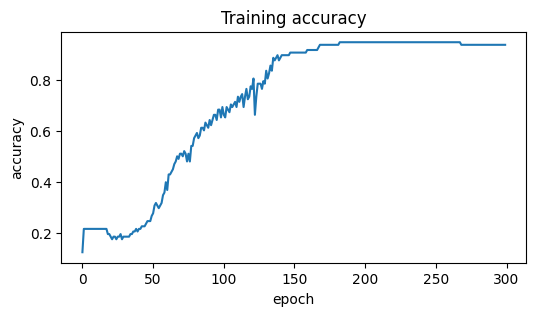

In [ ]:
# 3. train
hist = model.fit(X, y, epochs=300, verbose=0)
print("Final loss:", round(hist.history["loss"][-1], 3))
print("Final accuracy:", round(hist.history["accuracy"][-1], 3))

plt.figure(figsize=(6, 3))
plt.plot(hist.history["accuracy"])
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Training accuracy")
plt.show()

In [ ]:
# generate text from a seed
def generate(seed, n=10):
    out = seed
    for _ in range(n):
        ids = tok.texts_to_sequences([out])[0]
        ids = pad_sequences([ids], maxlen=maxlen - 1, padding="pre")
        nxt = int(np.argmax(model.predict(ids, verbose=0)))
        out += " " + tok.index_word.get(nxt, "")
    return out

for seed in ["the rain", "farmers", "when the clouds"]:
    print(generate(seed))

the rain fills the rivers the rain fills the wells and the


farmers the monsoon is not just rain it is the rhythm


when the clouds stay away the fields stay dry and the farmers wait


The model mostly reproduces phrases from the paragraph, which is expected with only ~110 words of training data. With the seed "farmers", which never starts a sentence in the paragraph, it jumps to a different sentence and joins two ideas into a new line. With more text and some randomness in picking the next word (sampling instead of argmax), the output would be more varied.